# 1.0 Sobre o Notebook

- O objetivo deste notebook é fazer as análises dos dados referentes ao dataset Olist
- Fonte dos dados: https://www.kaggle.com/datasets/olistbr/brazilian-ecommerce
- Os dados utilizados são gerados pelo notebook *02_limpeza.ipynb*, em data/processed

# 2.0 Problema de Negócio

- A Olist apresenta crescimento nas vendas e satisfação de clientes que justifiquem investimentos na expansão da plataforma?
    - As vendas estão crescendo? -> Analisar a evolução mensal dos pedidos e valor vendido
    - Os clientes estão satisfeitos? -> Analisar review score
    - O que prejudica a satisfação de um cliente? -> Analisar prazo de entrega x review_score
    - Onde estão as oportunidades? -> Olhar categorias e regiões com melhor/pior desempenho

# 3.0 Imports

In [1]:
import pandas as pd
from matplotlib import pyplot as plt
import numpy as np

# 4.0 Carregamento dos Dados Limpos

In [2]:
df_pedidos = pd.read_csv('../data/processed/pedidos_clean.csv', 
                         parse_dates=['order_purchase_timestamp', 'order_delivered_customer_date', 'order_estimated_delivery_date'])
df_clientes = pd.read_csv('../data/processed/clientes_clean.csv')
df_itens = pd.read_csv('../data/processed/itens_clean.csv')
df_avaliacoes = pd.read_csv('../data/processed/avaliacoes_clean.csv')
df_produtos = pd.read_csv('../data/processed/produtos_clean.csv')

## 4.1 Checagem das Tabelas

In [3]:
# checagem de pedidos
print(df_pedidos.shape)
print()
print(df_pedidos.dtypes)

(96211, 6)

order_id                                 object
customer_id                              object
order_status                             object
order_purchase_timestamp         datetime64[ns]
order_delivered_customer_date    datetime64[ns]
order_estimated_delivery_date    datetime64[ns]
dtype: object


In [4]:
# checagem de clientes
print(df_clientes.shape)
print()
print(df_clientes.dtypes)

(96211, 3)

customer_id           object
customer_unique_id    object
customer_state        object
dtype: object


In [5]:
# checagem de itens dos pedidos
print(df_itens.shape)
print()
print(df_itens.dtypes)

(109880, 4)

order_id          object
order_item_id      int64
product_id        object
price            float64
dtype: object


In [6]:
# checagem de avaliações
print(df_avaliacoes.shape)
print()
print(df_avaliacoes.dtypes)

(95045, 3)

review_id       object
order_id        object
review_score     int64
dtype: object


In [7]:
# checagem de produtos
print(df_produtos.shape)
print()
print(df_produtos.dtypes)

(32951, 2)

product_id               object
product_category_name    object
dtype: object


# 5.0 As Vendas Estão Crescendo?

In [8]:
# soma de price agrupando pelo order_id
soma_price = df_itens.groupby('order_id')['price'].sum().reset_index()

In [9]:
# renomeando a coluna 'price'
soma_price = soma_price.rename(columns={'price': 'valor_pedido'})

In [10]:
# limpeza das colunas que não serão usadas na tabela de pedidos
pedidos = df_pedidos.drop(columns=['customer_id', 'order_status', 'order_delivered_customer_date', 'order_estimated_delivery_date'])

In [11]:
# junção das tabelas
pedidos_data_price = pd.merge(pedidos, soma_price, how='inner', on='order_id', validate='1:1')

In [12]:
# checando se o resultado ficou com 96.211 linhas (em caso afirmativo nenhum pedido se perdeu)
pedidos_data_price.shape

(96211, 3)

In [13]:
# criando a coluna com o mês do pedido
pedidos_data_price['mes'] = pedidos_data_price['order_purchase_timestamp'].dt.to_period('M')

In [14]:
# criando tabela de métricas
metricas = pedidos_data_price.groupby('mes').agg(
    qtd_pedidos=('order_id', 'count'), 
    valor_vendido=('valor_pedido', 'sum'), 
    ticket_mediano=('valor_pedido', 'median')
)

In [15]:
# checando a tabela de métricas
# espera-se que tenha 20 linhas (meses), 96.211 pedidos e a soma de valor_vendido deve ser igual a soma de 'price' na tabela de itens
print(f'Quantidade de Linhas: {metricas.shape[0]}')
print(f'Quantidade de Pedidos: {metricas['qtd_pedidos'].sum()}')
print(f'Soma de valor_vendido: {metricas['valor_vendido'].sum().round(2)}')
print(f'Soma de price: {df_itens['price'].sum().round(2)}')

Quantidade de Linhas: 20
Quantidade de Pedidos: 96211
Soma de valor_vendido: 13181027.13
Soma de price: 13181027.13


In [16]:
# tabela de métricas por mês
metricas

,qtd_pedidos,valor_vendido,ticket_mediano
mes,,,
2017-01,750,111798.36,82.650
2017-02,1653,234223.40,84.900
2017-03,2546,359198.85,84.985
2017-04,2303,340669.68,87.890
2017-05,3546,489338.25,87.900
2017-06,3135,421923.37,79.900
2017-07,3872,481604.52,84.500
2017-08,4193,554699.70,79.990
2017-09,4150,607399.67,85.000


In [17]:
# crescimento acumulado entre jan-ago/2017 e jan-ago/2018
mascara_2017 = (pedidos_data_price['mes'] >= '2017-01') & (pedidos_data_price['mes'] <= '2017-08')
mascara_2018 = (pedidos_data_price['mes'] >= '2018-01') & (pedidos_data_price['mes'] <= '2018-08')
pedidos_2017 = pedidos_data_price[mascara_2017]
pedidos_2018 = pedidos_data_price[mascara_2018]

In [18]:
# total de pedidos e variação percentual no período
total_pedidos_2017 = len(pedidos_2017)
total_pedidos_2018 = len(pedidos_2018)

variacao_percent_pedidos = round((total_pedidos_2018 - total_pedidos_2017) / total_pedidos_2017 * 100, 2)

In [19]:
# total de valor vendido e variação percentual
valor_vendido_2017 = pedidos_2017['valor_pedido'].sum().round(2)
valor_vendido_2018 = pedidos_2018['valor_pedido'].sum().round(2)

variacao_percent_vendido = ((valor_vendido_2018 - valor_vendido_2017) / valor_vendido_2017 * 100).round(2)

In [20]:
# mediana do valor dos pedidos e variação percentual
mediana_pedidos_2017 = pedidos_2017['valor_pedido'].median().round(2)
mediana_pedidos_2018 = pedidos_2018['valor_pedido'].median().round(2)

variacao_percent_mediana = ((mediana_pedidos_2018 - mediana_pedidos_2017) / mediana_pedidos_2017 * 100).round(2)

In [21]:
# tabela comparativa

comparativo_vendas = pd.DataFrame(
    {
        'jan-ago/2017': [total_pedidos_2017, valor_vendido_2017, mediana_pedidos_2017],
        'jan-ago/2018': [total_pedidos_2018, valor_vendido_2018, mediana_pedidos_2018],
        'variação (%)': [variacao_percent_pedidos, variacao_percent_vendido, variacao_percent_mediana]
    },
    index=['Pedidos', 'Valor vendido', 'Ticket mediano']
)

comparativo_vendas

,jan-ago/2017,jan-ago/2018,variação (%)
Pedidos,21998.00,52783.00,139.94
Valor vendido,2993456.13,7218125.12,141.13
Ticket mediano,84.00,88.00,4.76


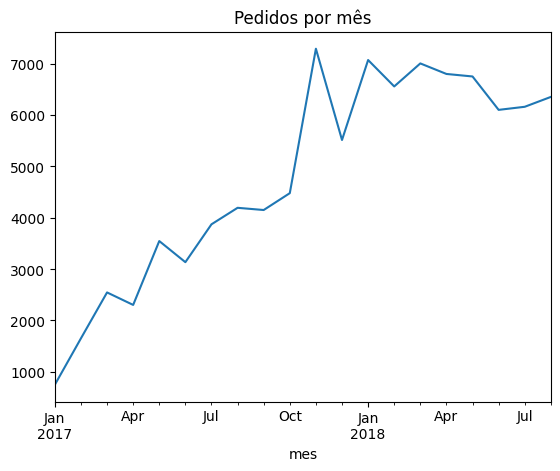

In [22]:
# gráfico com quantidade de pedidos por mês 
metricas['qtd_pedidos'].plot(title='Pedidos por mês')
plt.show()

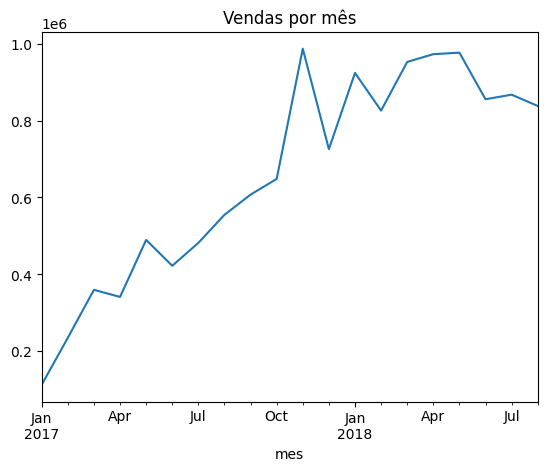

In [23]:
# gráfico com valor vendido por mês
metricas['valor_vendido'].plot(title='Vendas por mês')
plt.show()

In [24]:
# média mensal de pedidos em jan-ago/2018

mascara_2018_metricas = (metricas.index >= '2018-01') & (metricas.index <= '2018-08')
media_mensal_2018 = metricas.loc[mascara_2018_metricas, 'qtd_pedidos'].mean()

print(f'Média mensal de pedidos (jan-ago/2018): {round(media_mensal_2018, 0)}')

Média mensal de pedidos (jan-ago/2018): 6598.0


In [25]:
# pico de novembro/2017 em relação a outubro/2017
pedidos_out_2017 = metricas.loc['2017-10', 'qtd_pedidos']
pedidos_nov_2017 = metricas.loc['2017-11', 'qtd_pedidos']

var_nov_out_2017 = round((pedidos_nov_2017 - pedidos_out_2017) / pedidos_out_2017 * 100, 2)

print(f'Pedidos out/2017: {pedidos_out_2017}')
print(f'Pedidos nov/2017: {pedidos_nov_2017}')
print(f'Variação nov vs out/2017: {var_nov_out_2017}%')

Pedidos out/2017: 4478.0
Pedidos nov/2017: 7289.0
Variação nov vs out/2017: 62.77%


In [26]:
# média mensal de pedidos: 1º quadrimestre vs 2º quadrimestre de 2018

mascara_quad1_2018 = (metricas.index >= '2018-01') & (metricas.index <= '2018-04')
mascara_quad2_2018 = (metricas.index >= '2018-05') & (metricas.index <= '2018-08')

media_quad1_2018 = metricas.loc[mascara_quad1_2018, 'qtd_pedidos'].mean()
media_quad2_2018 = metricas.loc[mascara_quad2_2018, 'qtd_pedidos'].mean()

# variaçaõ percentual q1 e q2
var_percent_q1q2 = ((media_quad2_2018 - media_quad1_2018) / media_quad1_2018 * 100).round(2)

print(f'Média Q1 2018: {media_quad1_2018}')
print(f'Média Q2 2018: {media_quad2_2018}')
print(f'Variação Percentual Quad 1 vs Quad 2: {var_percent_q1q2}%')

Média Q1 2018: 6856.25
Média Q2 2018: 6339.5
Variação Percentual Quad 1 vs Quad 2: -7.54%


### Resposta: as vendas estão crescendo?

**Cresceram fortemente em 2017, mas estabilizaram em 2018, com leve queda no segundo quadrimestre.**

- Crescimento acumulado: de jan–ago/2017 para jan–ago/2018, os pedidos passaram de 21.998 para 52.783 (+139,9%) e o valor vendido de R$ 2,99 mi para R$ 7,22 mi (+141,1%).
- Origem do crescimento: o ticket mediano subiu apenas 4,8% (R$ 84 -> R$ 88). O crescimento veio do volume de pedidos, não de pedidos mais caros.
- Limitação do número: os 140% são inflados pelo efeito base. Jan/2017 teve apenas 750 pedidos, numa operação ainda em início, contra uma média de 6.598 pedidos/mês em 2018. O número reflete principalmente a fase de expansão de 2017.
- Momento atual: em 2018 o crescimento parou. A média mensal de pedidos caiu de 6.856 (jan–abr) para 6.340 (mai–ago), uma queda de 7,54%.
- Ponto fora da curva: o pico de nov/2017 (7.289 pedidos, +62,77% sobre outubro) é provavelmente efeito da Black Friday e não indica mudança de tendência.

Questão em aberto: os dados de vendas não explicam a desaceleração de 2018. Hipóteses a investigar nas próximas perguntas: piora na satisfação dos clientes, nos prazos de entrega, ou perda de força em categorias ou regiões específicas.

# 6.0 Os Clientes Estão Satisfeitos?

In [27]:
# criando uma cópia da tabela de avaliações
df_avaliacoes_new = df_avaliacoes.copy()

In [28]:
# apagando coluna que não será usada
df_avaliacoes_new = df_avaliacoes_new.drop(columns=['review_id'])

In [29]:
# criando coluna com nova classificação das avaliações
classificacao = {1: 'insatisfeito', 2: 'insatisfeito', 3: 'neutro', 4: 'satisfeito', 5:'satisfeito'}
df_avaliacoes_new['avaliacao_new'] = df_avaliacoes_new['review_score'].map(classificacao)

In [30]:
# checando a classificação: cada nota deve aparecer em um único grupo
pd.crosstab(df_avaliacoes_new['review_score'], df_avaliacoes_new['avaliacao_new'])

avaliacao_new,insatisfeito,neutro,satisfeito
review_score,,,
1,9251,0,0
2,2895,0,0
3,0,7839,0
4,0,0,18749
5,0,0,56311


In [31]:
# checando nulos na avaliação
df_avaliacoes_new['avaliacao_new'].isna().sum()

np.int64(0)

In [32]:
# junção com a tabela de pedidos (apenas id e data da compra)
pedidos_avaliacoes = pd.merge(
    df_pedidos[['order_id', 'order_purchase_timestamp']],
    df_avaliacoes_new,
    how='inner',
    on='order_id',
    validate='1:1'
)

In [33]:
# checando se a tabela tem 95.045 linhas
pedidos_avaliacoes.shape

(95045, 4)

In [34]:
# calculando o percentual de avaliações de acordo com a nova classificação
proporcao_reviews = pd.DataFrame({
    "quantidade": pedidos_avaliacoes["avaliacao_new"].value_counts(),
    "percentual": (pedidos_avaliacoes["avaliacao_new"].value_counts(normalize=True)*100).round(2)})

proporcao_reviews

,quantidade,percentual
avaliacao_new,,
satisfeito,75060,78.97
insatisfeito,12146,12.78
neutro,7839,8.25


In [35]:
# criando a coluna do mês da avaliação
pedidos_avaliacoes['mes'] = pedidos_avaliacoes['order_purchase_timestamp'].dt.to_period('M')

In [36]:
# marcando avaliações insatisfeitas
pedidos_avaliacoes['insatisfeito'] = pedidos_avaliacoes['avaliacao_new'] == 'insatisfeito'

In [37]:
# percentual de insatisfeitos por mês
insatisfeitos_por_mes = (pedidos_avaliacoes.groupby('mes')['insatisfeito'].mean() * 100).round(2)

In [38]:
insatisfeitos_por_mes

mes
2017-01    12.11
2017-02    11.13
2017-03    11.19
2017-04    12.83
2017-05    10.08
2017-06    10.68
2017-07     9.86
2017-08     9.39
2017-09    10.26
2017-10    11.07
2017-11    16.59
2017-12    14.43
2018-01    13.70
2018-02    19.32
2018-03    21.14
2018-04    11.76
2018-05    10.75
2018-06    10.00
2018-07     9.69
2018-08     9.54
Freq: M, Name: insatisfeito, dtype: float64

In [39]:
# checando resultado (precisa ter 20 linhas)
insatisfeitos_por_mes.shape

(20,)

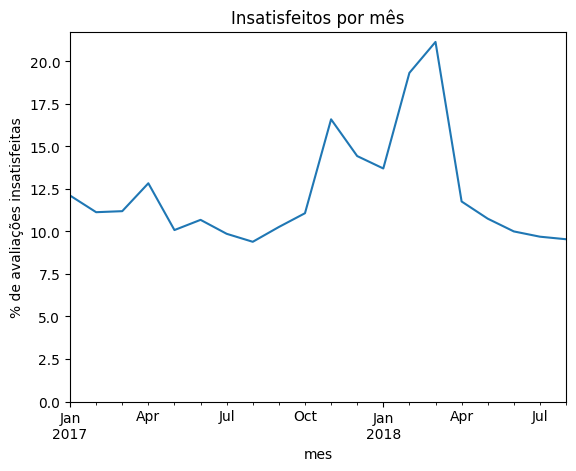

In [40]:
# gráfico com insatisfeitos por mês
insatisfeitos_por_mes.plot(title='Insatisfeitos por mês')
plt.ylim(0, None)
plt.ylabel('% de avaliações insatisfeitas')
plt.show()

In [41]:
# percentual de insatisfeitos: jan-ago/2017 vs jan-ago/2018 (calculado sobre as avaliações individuais)
mascara_aval_2017 = (pedidos_avaliacoes['mes'] >= '2017-01') & (pedidos_avaliacoes['mes'] <= '2017-08')
mascara_aval_2018 = (pedidos_avaliacoes['mes'] >= '2018-01') & (pedidos_avaliacoes['mes'] <= '2018-08')

insatisfeitos_2017 = round(pedidos_avaliacoes.loc[mascara_aval_2017, 'insatisfeito'].mean() * 100, 2)
insatisfeitos_2018 = round(pedidos_avaliacoes.loc[mascara_aval_2018, 'insatisfeito'].mean() * 100, 2)

print(f'Insatisfeitos jan-ago/2017: {insatisfeitos_2017}%')
print(f'Insatisfeitos jan-ago/2018: {insatisfeitos_2018}%')
print(f'Diferença: {round(insatisfeitos_2018 - insatisfeitos_2017, 2)} p.p.')

Insatisfeitos jan-ago/2017: 10.56%
Insatisfeitos jan-ago/2018: 13.34%
Diferença: 2.78 p.p.


In [42]:
# nível de insatisfação antes e depois do episódio de out/2017-mar/2018
mascara_antes = (pedidos_avaliacoes['mes'] >= '2017-01') & (pedidos_avaliacoes['mes'] <= '2017-09')
mascara_depois = (pedidos_avaliacoes['mes'] >= '2018-04') & (pedidos_avaliacoes['mes'] <= '2018-08')

insatisfeitos_antes = round(pedidos_avaliacoes.loc[mascara_antes, 'insatisfeito'].mean() * 100, 2)
insatisfeitos_depois = round(pedidos_avaliacoes.loc[mascara_depois, 'insatisfeito'].mean() * 100, 2)

print(f'Insatisfeitos antes do episódio (jan-set/2017): {insatisfeitos_antes}%')
print(f'Insatisfeitos depois do episódio (abr-ago/2018): {insatisfeitos_depois}%')

Insatisfeitos antes do episódio (jan-set/2017): 10.51%
Insatisfeitos depois do episódio (abr-ago/2018): 10.38%


In [43]:
# nível de insatisfação durante o episódio de out/2017-mar/2018
mascara_episodio = (pedidos_avaliacoes['mes'] >= '2017-10') & (pedidos_avaliacoes['mes'] <= '2018-03')

insatisfeitos_episodio = round(pedidos_avaliacoes.loc[mascara_episodio, 'insatisfeito'].mean() * 100, 2)

print(f'Insatisfeitos durante o episódio (out/2017 - mar/2018): {insatisfeitos_episodio}%')

Insatisfeitos durante o episódio (out/2017 - mar/2018): 16.39%


In [44]:
# pico de insatisfação
insatisfeitos_por_mes.loc['2018-03']

np.float64(21.14)

### Resposta: os clientes estão satisfeitos?

**Sim, na maior parte do período. Cerca de 79% de satisfeitos com insatisfação estável em torno de 10,5%. A exceção foi entre out/2017 e mar/2018, quando a insatisfação subiu para 16,4%, com pico de 21,14% em mar/2018, depois voltou ao nível anterior**

- Satisfação geral: 78,97% das avaliações são de clientes satisfeitos (notas 4 e 5), 8,25% neutras (nota 3) e 12,78% insatisfeitas (notas 1 e 2).
- Efeito do recorte: em relação à base bruta, os insatisfeitos caíram de 14,69% para 12,78% e os satisfeitos subiram de 77,07% para 78,97%. Isso era esperado, pois a análise considera apenas pedidos entregues. Pedidos cancelados ou indisponíveis tendem a gerar avaliações piores. Os neutros praticamente não mudaram (8,24% -> 8,25%).
- Nível normal: antes do episódio (jan–set/2017) a insatisfação foi de 10,51%; depois (abr–ago/2018), de 10,38%. Não há piora estrutural.
- Episódio de insatisfação: entre out/2017 e mar/2018 a insatisfação média subiu para 16,39%, com pior mês em mar/2018 (21,14%).
- Comparativo jan–ago: a insatisfação passou de 10,56% (2017) para 13,34% (2018), alta de 2,78 p.p. Essa diferença é explicada pelo episódio, que cobre jan–mar/2018, e não por uma piora ao longo de todo o ano.
- Relação com as vendas: o episódio começa junto com o pico de pedidos da Black Friday (nov/2017, +63% sobre outubro) e atravessa os meses de maior volume da série (nov/2017, jan/2018 e mar/2018, com cerca de 7.000 pedidos cada). Porém, em abr e mai/2018 o volume se manteve semelhante (6.798 e 6.749 pedidos) e a insatisfação voltou ao normal. Volume, sozinho, não explica o episódio.

Questão em aberto: os prazos de entrega pioraram entre out/2017 e mar/2018? Se sim, isso explicaria o episódio de insatisfação; a normalização a partir de abr/2018, mesmo com volume semelhante, sugeriria que a operação logística se ajustou. A pergunta 3 testa essa hipótese.

# 7.0 O que Prejudica a Satisfação de um Cliente?

In [45]:
# copia da tabela de pedidos
df_pedidos_new = df_pedidos.copy()

In [46]:
# excluindo colunas que não serão usadas
df_pedidos_new = df_pedidos_new.drop(columns=['customer_id', 'order_status'])

In [47]:
# checando limpeza
print(df_pedidos.shape)
print(df_pedidos_new.shape)

(96211, 6)
(96211, 4)


In [48]:
# checando os 8 pedidos sem data de entrega 
df_pedidos_new.isna().sum()

order_id                         0
order_purchase_timestamp         0
order_delivered_customer_date    8
order_estimated_delivery_date    0
dtype: int64

In [49]:
# excluindo 8 pedidos sem data de entrega
mascara_com_data = ~df_pedidos_new['order_delivered_customer_date'].isna()
df_pedidos_new = df_pedidos_new[mascara_com_data]

In [50]:
# checando limpeza (96.211 - 8 = 96.203)
print(df_pedidos_new.shape)
print(df_pedidos_new.isna().sum())

(96203, 4)
order_id                         0
order_purchase_timestamp         0
order_delivered_customer_date    0
order_estimated_delivery_date    0
dtype: int64


In [51]:
# diferença entre entrega real e entrega prometida
df_pedidos_new['dias_atraso'] = df_pedidos_new['order_delivered_customer_date'] - df_pedidos_new['order_estimated_delivery_date']

In [52]:
# transformando o resultado em dias inteiros
df_pedidos_new['dias_atraso'] = df_pedidos_new['dias_atraso'].dt.days

In [53]:
# estatística descritiva da coluna com os dias de atraso
df_pedidos_new['dias_atraso'].describe()

count    96203.000000
mean       -11.807969
std         10.088942
min       -147.000000
25%        -17.000000
50%        -12.000000
75%         -7.000000
max        188.000000
Name: dias_atraso, dtype: float64

In [54]:
# classificando pedidos como 'atrasado' ou 'no prazo'
df_pedidos_new['classificacao_entrega'] = np.where(df_pedidos_new['dias_atraso'] > 0, 'atrasado', 'no prazo')

In [55]:
# percentual de pedidos no prazo vs. atrasados
round(df_pedidos_new['classificacao_entrega'].value_counts(normalize=True)*100, 2)

classificacao_entrega
no prazo    93.21
atrasado     6.79
Name: proportion, dtype: float64

In [56]:
# junção da tabela de pedidos_new com avaliacoes_new
pedidos_avaliacoes_new = pd.merge(
    df_pedidos_new,
    df_avaliacoes_new,
    how='inner',
    on='order_id',
    validate='1:1'
)

In [57]:
# conferindo a tabela (o resultado deve ter entre 95.037 e 95.045 linhas a depender dos 8 pedidos que foram excluídos)
pedidos_avaliacoes_new.shape

(95037, 8)

In [58]:
# checando se a avaliação muda quando o pedido atrasa (% de cada grupo de avaliação por tipo de entrega)
round(pd.crosstab(pedidos_avaliacoes_new['classificacao_entrega'], pedidos_avaliacoes_new['avaliacao_new'], normalize='index')*100, 2)

avaliacao_new,insatisfeito,neutro,satisfeito
classificacao_entrega,,,
atrasado,62.36,10.85,26.79
no prazo,9.23,8.06,82.71


In [59]:
# calculando a representatividade de insatisfeitos na insatisfação geral
filtro_insatisfeitos = pedidos_avaliacoes_new['avaliacao_new'] == 'insatisfeito'
round(pedidos_avaliacoes_new.loc[filtro_insatisfeitos, 'classificacao_entrega'].value_counts(normalize=True)*100, 2)

classificacao_entrega
no prazo    67.39
atrasado    32.61
Name: proportion, dtype: float64

In [60]:
# criando a coluna mês 
df_pedidos_new['mes'] = df_pedidos_new['order_purchase_timestamp'].dt.to_period('M')

In [61]:
# marcando pedidos atrasados (True/False)
df_pedidos_new['atrasado'] = df_pedidos_new['classificacao_entrega'] == 'atrasado'

In [62]:
# checando resultado
round(df_pedidos_new['atrasado'].value_counts(normalize=True)*100, 2)

atrasado
False    93.21
True      6.79
Name: proportion, dtype: float64

In [63]:
# percentual de atrasados por mês
atrasados_por_mes = (df_pedidos_new.groupby('mes')['atrasado'].mean() * 100).round(2)

In [64]:
atrasados_por_mes

mes
2017-01     2.93
2017-02     2.96
2017-03     4.56
2017-04     6.56
2017-05     2.99
2017-06     3.03
2017-07     2.79
2017-08     2.91
2017-09     4.39
2017-10     4.18
2017-11    12.40
2017-12     7.46
2018-01     5.70
2018-02    14.13
2018-03    18.96
2018-04     4.50
2018-05     6.56
2018-06     1.16
2018-07     3.38
2018-08     6.19
Freq: M, Name: atrasado, dtype: float64

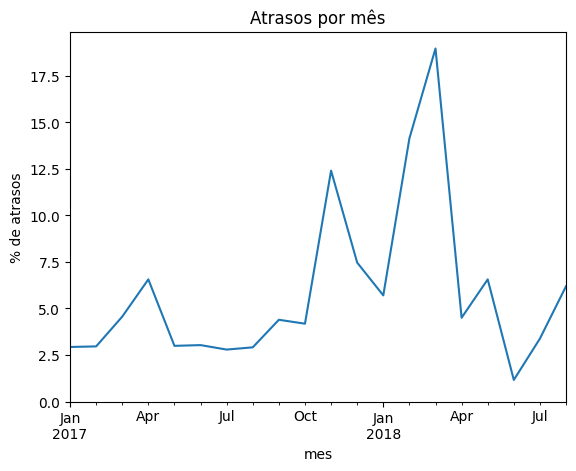

In [65]:
# gráfico com atrasos por mês
atrasados_por_mes.plot(title='Atrasos por mês')
plt.ylim(0, None)
plt.ylabel('% de atrasos')
plt.show()

In [66]:
# percentual de atrasos: jan-ago/2017 vs jan-ago/2018
mascara_atraso_2017 = (df_pedidos_new['mes'] >= '2017-01') & (df_pedidos_new['mes'] <= '2017-08')
mascara_atraso_2018 = (df_pedidos_new['mes'] >= '2018-01') & (df_pedidos_new['mes'] <= '2018-08')

atrasos_2017 = round(df_pedidos_new.loc[mascara_atraso_2017, 'atrasado'].mean() * 100, 2)
atrasos_2018 = round(df_pedidos_new.loc[mascara_atraso_2018, 'atrasado'].mean() * 100, 2)

print(f'Atrasos jan-ago/2017: {atrasos_2017}%')
print(f'Atrasos jan-ago/2018: {atrasos_2018}%')
print(f'Diferença: {round(atrasos_2018 - atrasos_2017, 2)} p.p.')

Atrasos jan-ago/2017: 3.5%
Atrasos jan-ago/2018: 7.73%
Diferença: 4.23 p.p.


In [67]:
# nível de atrasos antes e depois do episódio de out/2017-mar/2018
mascara_atraso_antes = (df_pedidos_new['mes'] >= '2017-01') & (df_pedidos_new['mes'] <= '2017-09')
mascara_atraso_depois = (df_pedidos_new['mes'] >= '2018-04') & (df_pedidos_new['mes'] <= '2018-08')

atrasos_antes = round(df_pedidos_new.loc[mascara_atraso_antes, 'atrasado'].mean() * 100, 2)
atrasos_depois = round(df_pedidos_new.loc[mascara_atraso_depois, 'atrasado'].mean() * 100, 2)

print(f'Atrasados antes do episódio (jan-set/2017): {atrasos_antes}%')
print(f'Atrasados depois do episódio (abr-ago/2018): {atrasos_depois}%')

Atrasados antes do episódio (jan-set/2017): 3.64%
Atrasados depois do episódio (abr-ago/2018): 4.42%


In [68]:
# nível de atrasos durante o episódio de out/2017-mar/2018
mascara_atrasos_episodio = (df_pedidos_new['mes'] >= '2017-10') & (df_pedidos_new['mes'] <= '2018-03')

atrasos_episodio = round(df_pedidos_new.loc[mascara_atrasos_episodio, 'atrasado'].mean() * 100, 2)

print(f'Atrasados durante o episódio (out/2017 - mar/2018): {atrasos_episodio}%')

Atrasados durante o episódio (out/2017 - mar/2018): 10.97%


In [69]:
# pico de atraso
atrasados_por_mes.loc['2018-03']

np.float64(18.96)

In [70]:
# tabela comparativa % de atrasos e % de insatisfeitos antes, durante e depois do episódio de 10/2017-03/2018

comparativo_atrasos_insatisfeitos = pd.DataFrame(
    {
        'Antes (jan-set/2017)': [atrasos_antes, insatisfeitos_antes],
        'Durante (out/2017-mar/2018)': [atrasos_episodio, insatisfeitos_episodio],
        'Depois (abr-ago/2018)': [atrasos_depois, insatisfeitos_depois]
    },
    index=['% atrasos', '% insatisfeitos']
)

comparativo_atrasos_insatisfeitos

,Antes (jan-set/2017),Durante (out/2017-mar/2018),Depois (abr-ago/2018)
% atrasos,3.64,10.97,4.42
% insatisfeitos,10.51,16.39,10.38


### Resposta: o que prejudica a satisfação de um cliente?

**O atraso na entrega. Os pedidos atrasados têm 62% de avaliações insatisfeitas, contra 9% dos entregues no prazo, e as duas curvas sobem e descem juntas ao longo do tempo. Embora sejam apenas 6,8% dos pedidos, os atrasos concentram um terço de toda a insatisfação.**

- Prazo prometido x realizado: a Olist promete prazos com folga. O pedido típico (mediana) chega 12 dias antes do prometido, e pelo menos 75% dos pedidos chegam com 7 dias ou mais de antecedência.
- Taxa de atraso: 93,21% dos pedidos foram entregues no prazo ou antes; 6,79% chegaram atrasados.
- Atraso x avaliação: nos pedidos atrasados, 62,36% das avaliações são insatisfeitas, contra 9,23% dos pedidos no prazo, cerca de 7 vezes mais. A satisfação cai de 82,71% para 26,79%.
- Concentração: os atrasos são 6,79% dos pedidos, mas respondem por 32,61% de toda a insatisfação. Um em cada três clientes insatisfeitos recebeu o pedido com atraso.
- Evolução no tempo: os atrasos acompanham o episódio de insatisfação identificado na pergunta 2. Antes (jan–set/2017) eram 3,64%; durante (out/2017–mar/2018) subiram para 10,97%, cerca de 3 vezes mais, com pico de 18,96% em mar/2018, o mesmo mês do pico de insatisfação (21,14%). Depois (abr–ago/2018) voltaram para perto do nível anterior (4,42%), e a insatisfação voltou ao normal (10,38%).
- Resposta à questão da pergunta 2: em abr–mai/2018 o volume de pedidos se manteve alto, mas os atrasos caíram e a insatisfação caiu junto. O que acompanha a insatisfação é o atraso, não o volume.
- Força da evidência: são duas evidências independentes apontando na mesma direção, uma por pedido (atrasado x no prazo) e outra no tempo (curvas que sobem e descem juntas). Trata-se de uma associação forte e consistente, não de uma prova de causa. Outros fatores (produto errado, avaria) também geram insatisfação e não foram medidos.
- Nota metodológica: os 8 pedidos sem data de entrega foram excluídos desta análise; como todos tinham avaliação, a base ficou com 95.037 avaliações (contra 95.045 na pergunta 2).

Questão em aberto: os atrasos se concentram em regiões ou categorias específicas? Se sim, o investimento em logística pode ser direcionado onde o problema é maior, e não espalhado pela operação inteira. A pergunta 4 investiga isso.

# 8.0 Onde Estão as Oportunidades?

In [71]:
# recuperando 'customer_id' para criar uma nova tabela
ponte_clientes = df_pedidos[['customer_id', 'order_id']]

In [72]:
# junção de 'ponte_clientes' com 'oportunidades'
oportunidades = pd.merge(df_pedidos_new, ponte_clientes, on='order_id', how='left', validate='1:1')

In [73]:
# junção de oportunidades com df_clientes
oportunidades = pd.merge(oportunidades, df_clientes, on='customer_id', how='left', validate='1:1')

In [74]:
# checando nulos
oportunidades.isna().sum()

order_id                         0
order_purchase_timestamp         0
order_delivered_customer_date    0
order_estimated_delivery_date    0
dias_atraso                      0
classificacao_entrega            0
mes                              0
atrasado                         0
customer_id                      0
customer_unique_id               0
customer_state                   0
dtype: int64

In [75]:
# checando linhas
oportunidades.shape

(96203, 11)

In [76]:
# junção com a tabela df_avaliacoes_new
oportunidades = pd.merge(oportunidades, df_avaliacoes_new[['order_id', 'avaliacao_new']], on='order_id', how='left', validate='1:1')

In [77]:
# checando linhas
oportunidades.shape

(96203, 12)

In [78]:
# checando nulos
oportunidades.isna().sum()

order_id                            0
order_purchase_timestamp            0
order_delivered_customer_date       0
order_estimated_delivery_date       0
dias_atraso                         0
classificacao_entrega               0
mes                                 0
atrasado                            0
customer_id                         0
customer_unique_id                  0
customer_state                      0
avaliacao_new                    1166
dtype: int64

### Observação: 
- Os nulos de *avaliacao_new* eram esperados. São 523 pedidos com mais de uma avaliação (removidos na limpeza) somados a 643 pedidos entregues sem avaliação -> 523 + 643 = 1.166. 
- Para cálculos de percentual de atrasos, toda a tabela será usada (96.203 pedidos). 
- Para cálculos de percentual de insatisfeitos serão usadas apenas linhas com avaliação (96.203 - 1.166 = 95.037 pedidos).

In [79]:
# criando coluna de macrorregião
regiao = {
    'Norte': ['AC', 'AP', 'AM', 'PA', 'RO', 'RR', 'TO'],
    'Nordeste': ['AL', 'BA', 'CE', 'MA', 'PB', 'PE', 'PI', 'RN', 'SE'],
    'Centro-Oeste': ['DF', 'GO', 'MT', 'MS'],
    'Sudeste': ['ES', 'MG', 'RJ', 'SP'],
    'Sul': ['PR', 'RS', 'SC']
}

# invertendo o dicionário: de região -> lista de UFs para UF -> região
uf_para_regiao = {}
for nome_regiao, ufs in regiao.items():
    for uf in ufs:
        uf_para_regiao[uf] = nome_regiao

oportunidades['regiao'] = oportunidades['customer_state'].map(uf_para_regiao)

In [80]:
# checando aplicação das macrorregiões
print(len(uf_para_regiao))
print()
print(oportunidades.isna().sum())

27

order_id                            0
order_purchase_timestamp            0
order_delivered_customer_date       0
order_estimated_delivery_date       0
dias_atraso                         0
classificacao_entrega               0
mes                                 0
atrasado                            0
customer_id                         0
customer_unique_id                  0
customer_state                      0
avaliacao_new                    1166
regiao                              0
dtype: int64


In [81]:
# apenas pedidos com avaliação (cálculo de insatisfação)
oportunidades_avaliadas = oportunidades[oportunidades['avaliacao_new'].notna()]

In [82]:
# checando oportunidades_avaliadas
print(oportunidades_avaliadas.shape)
print()
print(oportunidades_avaliadas.columns)

(95037, 13)

Index(['order_id', 'order_purchase_timestamp', 'order_delivered_customer_date',
       'order_estimated_delivery_date', 'dias_atraso', 'classificacao_entrega',
       'mes', 'atrasado', 'customer_id', 'customer_unique_id',
       'customer_state', 'avaliacao_new', 'regiao'],
      dtype='object')


In [83]:
# criando tabela de métricas
metricas_regiao = oportunidades.groupby('regiao').agg(
    pedidos=('order_id', 'count'),
    atrasos=('atrasado', 'sum'),
    pct_atrasos=('atrasado', 'mean')
)

# convertendo proporção em percentual
metricas_regiao['pct_atrasos'] = (metricas_regiao['pct_atrasos'] * 100).round(2)

In [84]:
# participação de cada região no total de pedidos (%)
metricas_regiao['pct_pedidos'] = (metricas_regiao['pedidos'] / metricas_regiao['pedidos'].sum() * 100).round(2)

In [85]:
# participação de cada região no total de atrasos da Olist
metricas_regiao['pct_do_total_atrasos'] = (metricas_regiao['atrasos'] / metricas_regiao['atrasos'].sum() * 100).round(2)

In [86]:
# ordenando por pedidos
metricas_regiao = metricas_regiao.sort_values('pedidos', ascending=False)

In [87]:
# taxa média de atrasos da Olist (todos os pedidos entregues)
media_atrasos_olist = round(oportunidades['atrasado'].mean() * 100, 2)
media_atrasos_olist

np.float64(6.79)

In [88]:
# simulação - quantos atrasos seriam evitados se o Nordeste caísse da taxa atual para a média Olist (6,79%)
round(metricas_regiao.loc['Nordeste', 'pedidos'] * (metricas_regiao.loc['Nordeste', 'pct_atrasos'] - media_atrasos_olist) / 100)

538

In [89]:
# simulação - atrasos evitados se o Sudeste reduzisse 1 p.p. na taxa de atraso
reducao_pp = 1
round(metricas_regiao.loc['Sudeste', 'pedidos'] * reducao_pp / 100)

660

In [90]:
# criando coluna de % da população com base nos dados do IBGE -> estimativa de 2026
# Fonte: https://www.ibge.gov.br/estatisticas/sociais/populacao/9103-estimativas-de-populacao.html)

pop_br = {
    'Sudeste': 41.55,
    'Nordeste': 26.78,
    'Sul': 14.70,
    'Norte': 8.84,
    'Centro-Oeste': 8.12
}

metricas_regiao['pct_populacao'] = metricas_regiao.index.map(pop_br)

### Observação: 
- Limitação: os dados analisados são referentes a pedidos ocorridos em 2017 e 2018. Para a população por região foi utilizada a estimativa do IBGE de 2026. 

In [91]:
# calculando índice de penetração em uma nova coluna

metricas_regiao['indice_penetracao'] = (metricas_regiao['pct_pedidos'] / metricas_regiao['pct_populacao']).round(2)

In [92]:
# % de insatisfeitos por região (apenas pedidos avaliados)
insatisfeito_avaliadas = oportunidades_avaliadas['avaliacao_new'] == 'insatisfeito'
insatisfeitos_por_regiao = insatisfeito_avaliadas.groupby(oportunidades_avaliadas['regiao']).mean() * 100

# adicionando a coluna na tabela de métricas (o pandas alinha pelo nome da região)
metricas_regiao['pct_insatisfeitos'] = insatisfeitos_por_regiao.round(2)

In [93]:
# checando a média geral de insatisfeitos (deve ficar próximo de 12,78%)
round(insatisfeito_avaliadas.mean()*100, 2)

np.float64(12.78)

In [94]:
# tabela final
metricas_regiao

,pedidos,atrasos,pct_atrasos,pct_pedidos,pct_do_total_atrasos,pct_populacao,indice_penetracao,pct_insatisfeitos
regiao,,,,,,,,
Sudeste,66020,4045,6.13,68.63,61.94,41.55,1.65,12.34
Sul,13767,815,5.92,14.31,12.48,14.70,0.97,11.78
Nordeste,9015,1150,12.76,9.37,17.61,26.78,0.35,16.81
Centro-Oeste,5610,367,6.54,5.83,5.62,8.12,0.72,13.16
Norte,1791,154,8.60,1.86,2.36,8.84,0.21,15.22


### Resposta: onde estão as oportunidades?

**Na logística das regiões Nordeste e Sudeste, por motivos diferentes. O Nordeste tem o dobro da taxa média de atrasos, a maior insatisfação e é a região mais sub-representada em relação à população; é uma oportunidade de crescimento travada pela experiência de entrega. O Sudeste tem taxa de atraso abaixo da média, mas concentra 62% de todos os atrasos; qualquer melhoria tem o maior impacto absoluto.**

- Concentração da base: o Sudeste responde por 68,63% dos pedidos, contra 41,55% da população (índice de penetração de 1,65). Nordeste (0,35) e Norte (0,21) são as regiões mais sub-representadas; o Sul está em linha com a população (0,97).
- Atrasos por região: a média da Olist é 6,79%. O Nordeste tem 12,76%, quase o dobro, e responde por 17,61% dos atrasos tendo apenas 9,37% dos pedidos. O Norte vem em seguida (8,60%). Sudeste (6,13%), Sul (5,92%) e Centro-Oeste (6,54%) estão abaixo ou perto da média.
- Insatisfação por região: a ordem é exatamente a mesma dos atrasos. Nordeste 16,81%, Norte 15,22%, Centro-Oeste 13,16%, Sudeste 12,34% e Sul 11,78% (média geral: 12,78%).
- Terceira evidência da relação atraso x insatisfação: o padrão já aparecia por pedido e ao longo do tempo (pergunta anterior) e agora se repete entre as regiões. Com apenas 5 regiões, isso reforça o padrão, mas não é uma prova isolada; a força do argumento está nas três evidências apontarem na mesma direção.
- Dois tipos de oportunidade:
    - Nordeste (corrigir uma anomalia): se a taxa de atraso caísse para a média da Olist, cerca de 538 atrasos seriam evitados no período. Somado à baixa penetração, é onde a melhoria logística também pode destravar crescimento.
    - Sudeste (ganho de escala): uma redução de apenas 1 p.p. na taxa de atraso evitaria cerca de 660 atrasos, mais do que corrigir por completo a anomalia do Nordeste.
- Hipóteses: a causa dos atrasos maiores no Nordeste não foi identificada; uma hipótese a investigar é a distância entre vendedores e clientes. A baixa penetração também é explicada em parte por renda e acesso ao e-commerce, que não foram medidos.
- Limitações: a participação da população vem da estimativa do IBGE de 2026, enquanto os pedidos são de 2017–2018; a distribuição regional da população muda pouco nesse intervalo. O detalhamento por UF e a análise por categoria ficam para o próximo ciclo.

Questão em aberto: com crescimento estagnado em 2018, a satisfação ligada ao atraso e as oportunidades concentradas em logística regional, a Olist justifica novo investimento? A seção 9 responde à pergunta norteadora.

# 9.0 Conclusão e Recomendação